# 🏡 Tutorial de Machine Learning: Predicción de Precios de Viviendas con Regresión Lineal

En este tutorial aprenderemos a utilizar algoritmos de **Machine Learning** para predecir el precio de las viviendas. Utilizaremos un conjunto de datos que contiene información demográfica y física de diferentes áreas, y aplicaremos dos técnicas fundamentales: **Regresión Lineal Simple** y **Regresión Lineal Múltiple**.

---

## 🎯 1. Planteamiento del Problema

### El Problema
El mercado inmobiliario es altamente dinámico y complejo. El precio de una vivienda no es un valor aleatorio, sino que está influenciado por múltiples factores: el tamaño de la propiedad, la cantidad de habitaciones, la antigüedad, y factores externos como el ingreso promedio de los vecinos o la densidad poblacional del área. Para compradores, vendedores e inversores, estimar con precisión el valor de una propiedad basándose en datos históricos es un desafío constante.

### Pregunta Problema
¿Cómo podemos predecir el precio de venta de una vivienda utilizando características demográficas y físicas del área donde se encuentra, mediante modelos de Machine Learning?

### Objetivo
Desarrollar modelos de Regresión Lineal (Simple y Múltiple) que permitan estimar el precio de una vivienda (`Price`) en función de variables predictoras como el ingreso promedio del área, la edad de las casas, el número de habitaciones y la población.

### Propósito
Crear una herramienta predictiva accesible y comprensible que demuestre, paso a paso, cómo aplicar algoritmos de Machine Learning en Python para tomar decisiones informadas y basadas en datos en el sector inmobiliario.

## 🧠 2. Marco Teórico: ¿Qué es la Regresión Lineal?

La **Regresión Lineal** es un algoritmo de **Machine Learning Supervisado** que se utiliza para predecir un valor continuo (como el precio de una casa, la temperatura o las ventas). Su objetivo es encontrar la "línea recta" (o hiperplano, en múltiples dimensiones) que mejor se ajuste a la relación entre nuestras variables.

### Tipos de Regresión Lineal que veremos:
1. **Regresión Lineal Simple**: Utiliza **una sola variable** independiente para predecir la variable dependiente.
   - *Ecuación:* $y = \beta_0 + \beta_1x$
   - *Ejemplo:* Predecir el precio de una casa basándonos **únicamente** en la población del área.
   
2. **Regresión Lineal Múltiple**: Utiliza **dos o más variables** independientes para predecir la variable dependiente.
   - *Ecuación:* $y = \beta_0 + \beta_1x_1 + \beta_2x_2 + ... + \beta_nx_n$
   - *Ejemplo:* Predecir el precio usando el ingreso, la edad de la casa, habitaciones y población al mismo tiempo.

### Métricas de Evaluación
Para saber qué tan bueno es nuestro modelo, usaremos:
- **MSE (Mean Squared Error)**: Mide el promedio de los errores al cuadrado. Entre más cerca a 0, mejor.
- **R² (R-cuadrado)**: Nos dice qué porcentaje de la variabilidad de los datos es explicada por nuestro modelo (un valor de 0.91 significa que el modelo explica el 91% de los datos).

## 📊 3. Diccionario de Variables

A continuación, se detallan las variables de nuestro dataset, su tipo de dato y cómo las utilizaremos en nuestro modelo de Machine Learning.

| Variable | Tipo de Dato | Descripción | Uso en Machine Learning (Regresión) |
| :--- | :--- | :--- | :--- |
| **`Avg. Area Income`** | Numérica (Continua) | Ingreso promedio de los habitantes del área. | **Feature (Variable Independiente)**. A mayor ingreso en el área, se espera que los precios de las viviendas sean más altos. |
| **`Avg. Area House Age`** | Numérica (Continua) | Edad promedio de las casas en el área. | **Feature (Variable Independiente)**. Nos ayuda a entender si las casas más nuevas (o más antiguas) tienen mayor valor en la zona. |
| **`Avg. Area Number of Rooms`** | Numérica (Continua) | Promedio de habitaciones totales por casa en el área. | **Feature (Variable Independiente)**. Más habitaciones suele correlacionarse con casas más grandes y costosas. |
| **`Avg. Area Number of Bedrooms`** | Numérica (Continua) | Promedio de dormitorios por casa en el área. | **Feature (Variable Independiente)**. Similar a la anterior, pero enfocada en dormitorios, un factor clave para familias. |
| **`Area Population`** | Numérica (Continua) | Población promedio del área. | **Feature (Variable Independiente)**. La usaremos tanto en la regresión simple como en la múltiple para ver su impacto individual y grupal. |
| **`Price`** | Numérica (Continua) | Precio de venta de la vivienda. | **Target (Variable Dependiente)**. Es la variable que nuestro modelo intentará aprender a predecir. |
| **`Address`** | Texto (String) | Dirección física de la propiedad. | **Se elimina**. Las direcciones son texto único y no aportan un patrón matemático útil para la regresión lineal. |

---
## 💻 4. Importar Librerías

Comenzamos importando todas las herramientas necesarias para manipular datos, visualizar gráficos y construir nuestro modelo de Machine Learning.

In [1]:
# ==============================================================================
# PASO 1: IMPORTAR LIBRERÍAS
# ==============================================================================
# Importamos las herramientas necesarias para manipular datos, hacer gráficos
# y crear nuestro modelo de Machine Learning.

import pandas as pd             # Para cargar y manipular los datos (DataFrames)
import numpy as np              # Para operaciones matemáticas y matrices
import matplotlib.pyplot as plt # Para crear gráficos básicos
import seaborn as sb            # Para gráficos estadísticos más atractivos (como mapas de calor)

# Librerías de Machine Learning (Scikit-Learn)
from sklearn.linear_model import LinearRegression       # El algoritmo de Regresión Lineal
from sklearn.metrics import mean_squared_error, r2_score # Para evaluar qué tan bueno es el modelo
from sklearn.model_selection import train_test_split    # Para dividir los datos en entrenamiento y prueba

---
## 📂 5. Cargar y Explorar los Datos

Cargamos el archivo `housing.csv` en un DataFrame de pandas y realizamos una exploración inicial para entender la estructura de los datos.

In [4]:
# ==============================================================================
# PASO 2: CARGAR Y EXPLORAR LOS DATOS
# ==============================================================================
# Cargamos el archivo CSV en un DataFrame de pandas llamado 'df'
df = pd.read_csv('housing.csv')

# Mostramos las primeras 5 filas para ver cómo se ven los datos
print("--- Primeras 5 filas del dataset ---")
display(df.head())

# Mostramos información general: tipos de datos y si hay valores nulos
print("\n--- Información general del dataset ---")
df.info()

# Estadísticas descriptivas (media, desviación estándar, mínimos, máximos)
print("\n--- Estadísticas descriptivas ---")
df.describe()

--- Primeras 5 filas del dataset ---


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



--- Información general del dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

--- Estadísticas descriptivas ---


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


---
## 🧹 6. Preprocesamiento y Análisis de Correlación

Antes de entrenar el modelo, debemos:
1. **Eliminar la columna `Address`** porque es texto y no aporta información matemática útil.
2. **Calcular la matriz de correlación** para ver qué variables están más relacionadas con el precio.

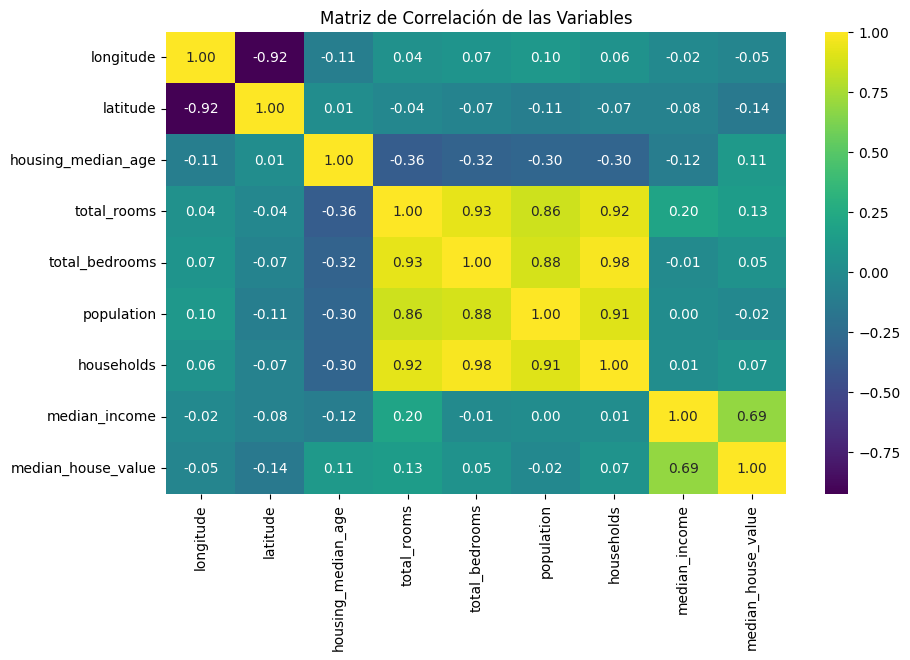

In [5]:
# ==============================================================================
# PASO 3: PREPROCESAMIENTO Y ANÁLISIS DE CORRELACIÓN
# ==============================================================================
# 1. Eliminamos la columna 'ocean_proximity' porque es texto y no sirve para la regresión.
# (El dataset real de California contiene 'ocean_proximity' en lugar de 'Address')
df_numeric = df.drop('ocean_proximity', axis=1, errors='ignore')

# 2. Calculamos la matriz de correlación.
# Esto nos dice qué tan fuertemente relacionadas están las variables entre sí.
corr = df_numeric.corr()

# 3. Creamos un mapa de calor (Heatmap) para visualizar la correlación.
plt.figure(figsize=(10, 6))
sb.heatmap(corr, annot=True, cmap='viridis', fmt=".2f")
plt.title("Matriz de Correlación de las Variables")
plt.show()

# NOTA: En este dataset, 'median_income' tiene una correlación muy fuerte con 'median_house_value',
# por lo que es una excelente candidata para la Regresión Lineal Simple.

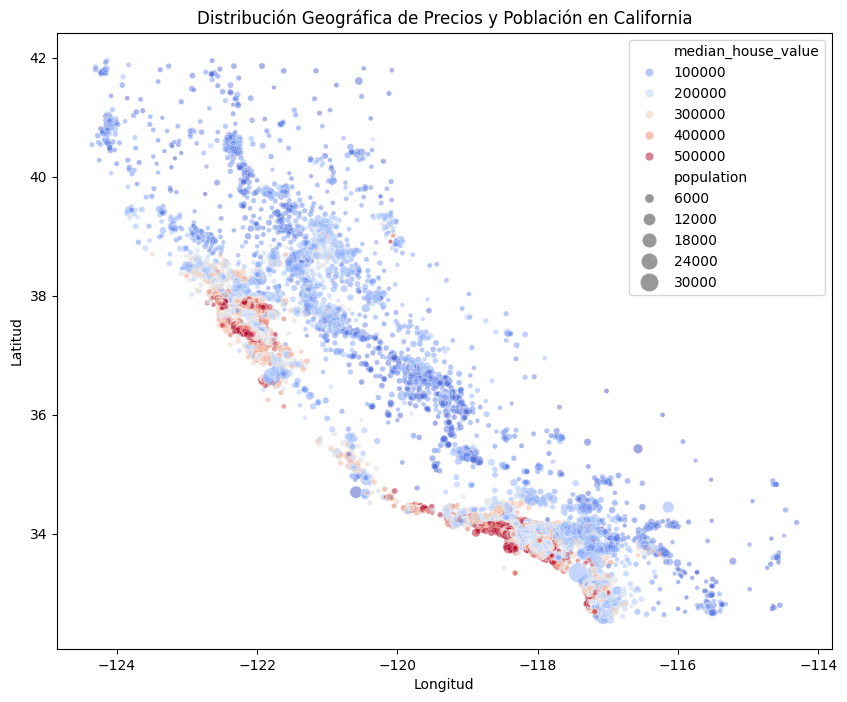

In [17]:
import seaborn as sb
import matplotlib.pyplot as plt

# Corregimos 'datos' por 'df_clean', que es el DataFrame cargado y limpio en el notebook
plt.figure(figsize=(10, 8))
sb.scatterplot(x="longitude", y="latitude", data=df_clean, hue="median_house_value", palette="coolwarm",
               size="population", sizes=(10, 200), alpha=0.5)

plt.title("Distribución Geográfica de Precios y Población en California")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.show()

---
## 📈 7. Regresión Lineal Simple

En esta sección, vamos a predecir el precio de la vivienda (`Price`) utilizando **una sola variable**: la Población del Área (`Area Population`).

El modelo aprenderá la ecuación de la línea recta que mejor relacione la población con el precio.

Intersección (β0): 45085.58
Coeficiente (β1): 41793.85

Esto significa que por cada punto de incremento en el ingreso mediano, el precio sube aproximadamente $ 41793.85


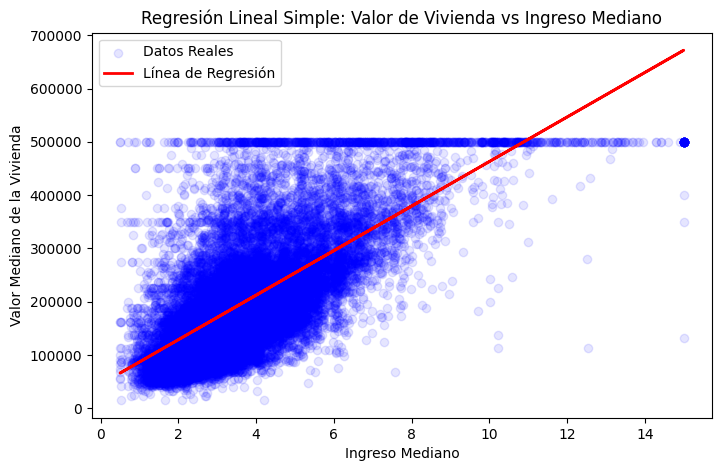

In [7]:
# ==============================================================================
# PASO 4: REGRESIÓN LINEAL SIMPLE
# ==============================================================================
# Definimos nuestra variable independiente (X) y la dependiente (y)
# Usaremos 'median_income' por su fuerte correlación con 'median_house_value'
x = df[['median_income']] # Usamos doble corchete [[' ']] para que sea un DataFrame
y = df['median_house_value'] # Variable a predecir (Target)

# Creamos la instancia del modelo
model_simple = LinearRegression()

# Entrenamos el modelo con los datos (fit)
model_simple.fit(x, y)

# Hacemos predicciones con los mismos datos para ver cómo se ajusta
y_pred_simple = model_simple.predict(x)

# Mostramos la ecuación que aprendió el modelo
print(f"Intersección (β0): {model_simple.intercept_:.2f}")
print(f"Coeficiente (β1): {model_simple.coef_[0]:.2f}")
print("\nEsto significa que por cada punto de incremento en el ingreso mediano, el precio sube aproximadamente $", round(model_simple.coef_[0], 2))

# Graficamos los datos reales y la línea de regresión
plt.figure(figsize=(8, 5))
plt.scatter(x, y, color='blue', alpha=0.1, label='Datos Reales')
plt.plot(x, y_pred_simple, color='red', lw=2, label='Línea de Regresión')
plt.xlabel("Ingreso Mediano")
plt.ylabel("Valor Mediano de la Vivienda")
plt.title("Regresión Lineal Simple: Valor de Vivienda vs Ingreso Mediano")
plt.legend()
plt.show()

---
## 🚀 8. Regresión Lineal Múltiple

Ahora daremos un paso más. En la vida real, el precio de una casa no depende de un solo factor.
En esta sección, utilizaremos **todas las variables numéricas disponibles** (Ingreso, Edad, Habitaciones, Dormitorios y Población) para predecir el precio.

Además, dividiremos nuestros datos en dos grupos:
1. **Entrenamiento (80%)**: Para que el modelo aprenda.
2. **Prueba (20%)**: Para evaluar el modelo con datos que nunca ha visto (evitar el sobreajuste).

In [8]:
# ==============================================================================
# PASO 5: REGRESIÓN LINEAL MÚLTIPLE
# ==============================================================================
# 1. Limpieza rápida: El dataset real de California contiene algunos valores nulos en 'total_bedrooms'.
# Los rellenamos con la mediana antes de entrenar.
df_clean = df.copy()
df_clean['total_bedrooms'] = df_clean['total_bedrooms'].fillna(df_clean['total_bedrooms'].median())

# 2. Separamos las variables independientes (X) de la variable a predecir (y)
# Eliminamos la variable objetivo y las columnas de texto
X = df_clean.drop(['median_house_value', 'ocean_proximity'], axis=1, errors='ignore')
y = df_clean['median_house_value']

# 3. Dividimos los datos en conjuntos de Entrenamiento (80%) y Prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Datos de entrenamiento: {X_train.shape[0]} filas")
print(f"Datos de prueba: {X_test.shape[0]} filas")

# 4. Creamos y entrenamos el modelo múltiple
model_multiple = LinearRegression()
model_multiple.fit(X_train, y_train)

Datos de entrenamiento: 16512 filas
Datos de prueba: 4128 filas


LinearRegression()

---
## 📊 9. Evaluar el Modelo

Ahora que el modelo ya aprendió, vamos a evaluar qué tan bien predice usando el conjunto de **prueba** (datos que nunca vio durante el entrenamiento).

In [9]:
# ==============================================================================
# PASO 6: EVALUAR EL MODELO
# ==============================================================================
# Hacemos predicciones sobre el conjunto de PRUEBA (datos que el modelo nunca ha visto)
y_pred_multiple = model_multiple.predict(X_test)

# Calculamos las métricas de evaluación
mse = mean_squared_error(y_test, y_pred_multiple)
r2 = r2_score(y_test, y_pred_multiple)

print("--- Métricas de Evaluación del Modelo Múltiple ---")
print(f"Mean Squared Error (MSE): {mse:,.2f}")
print(f"R-squared (R²): {r2:.4f}")
print("\nInterpretación:")
print(f"El modelo es capaz de explicar aproximadamente el {r2*100:.2f}% de la variación en los precios de las viviendas.")

--- Métricas de Evaluación del Modelo Múltiple ---
Mean Squared Error (MSE): 5,059,928,371.17
R-squared (R²): 0.6139

Interpretación:
El modelo es capaz de explicar aproximadamente el 61.39% de la variación en los precios de las viviendas.


---
## 🎮 10. Simulador de Predicción

Vamos a crear un pequeño simulador interactivo donde el usuario ingresa los datos de una vivienda y el modelo predice su precio.

In [15]:
# ==============================================================================
# PASO 7: PREDICCIÓN INTERACTIVA (SIMULADOR ACTUALIZADO)
# ==============================================================================
import pandas as pd

print("🏡 SIMULADOR DE PRECIOS DE VIVIENDAS (California) 🏡")
print("Por favor, ingresa las características solicitadas.")
print("Nota: Las coordenadas geográficas (latitud/longitud) se calcularán automáticamente con la mediana de la región.\n")

# Definimos las columnas que el usuario va a ingresar manualmente
manual_features = [
    'housing_median_age',
    'total_rooms',
    'total_bedrooms',
    'population',
    'households',
    'median_income'
]

user_input = {}

# Solicitar de forma interactiva los datos al usuario mostrando los rangos mínimos y máximos reales
for feature in manual_features:
    min_val = df_clean[feature].min()
    max_val = df_clean[feature].max()

    # Mensajes personalizados para guiar mejor al usuario
    desc = feature.replace('_', ' ').capitalize()
    if feature == 'median_income':
        desc = "Ingreso promedio de la zona (en decenas de miles de dólares, ej: 3.5 = $35,000)"

    while True:
        try:
            val_input = input(f"➡️ {desc} [Rango sugerido: {min_val:.1f} a {max_val:.1f}]: ")
            value = float(val_input)
            user_input[feature] = value
            break
        except ValueError:
            print(f"⚠️ Entrada inválida. Por favor, ingresa un número dentro del rango sugerido ({min_val:.1f} - {max_val:.1f}).")

# Asignar automáticamente los valores medianos para latitud y longitud del dataset original
user_input['longitude'] = df_clean['longitude'].median()
user_input['latitude'] = df_clean['latitude'].median()

# Convertimos el diccionario a un DataFrame con el orden de columnas exacto que espera el modelo
input_data = pd.DataFrame([user_input])
input_data = input_data[X_train.columns]

# Realizamos la predicción con el modelo múltiple entrenado
predicted_price = model_multiple.predict(input_data)

# Mostramos el resultado de la estimación
print("\n" + "="*65)
print(f"💰 PRECIO ESTIMADO DE LA VIVIENDA EN ESTA ZONA: ${max(0, predicted_price[0]):,.2f}")
print("="*65)

🏡 SIMULADOR DE PRECIOS DE VIVIENDAS (California) 🏡
Por favor, ingresa las características solicitadas.
Nota: Las coordenadas geográficas (latitud/longitud) se calcularán automáticamente con la mediana de la región.

➡️ Housing median age [Rango sugerido: 1.0 a 52.0]: 5
➡️ Total rooms [Rango sugerido: 2.0 a 39320.0]: 4
➡️ Total bedrooms [Rango sugerido: 1.0 a 6445.0]: 1
➡️ Population [Rango sugerido: 3.0 a 35682.0]: 10
➡️ Households [Rango sugerido: 1.0 a 6082.0]: 10
➡️ Ingreso promedio de la zona (en decenas de miles de dólares, ej: 3.5 = $35,000) [Rango sugerido: 0.5 a 15.0]: 0.8

💰 PRECIO ESTIMADO DE LA VIVIENDA EN ESTA ZONA: $57,455.18


---
## 💡 Conclusiones y Recomendaciones

### ¿Qué aprendimos?
1. **Regresión Lineal Simple**: Útil para entender la relación entre **una variable** y el precio.
2. **Regresión Lineal Múltiple**: Mucho más precisa porque considera **varios factores** al mismo tiempo.
3. **División de datos**: Es fundamental separar los datos en entrenamiento y prueba para evaluar el modelo de forma justa.
4. **Métricas de evaluación**: El R² nos dice qué tan bien el modelo explica los datos.

### 🔍 Ideas para mejorar el modelo:
- Probar modelos más avanzados como **Random Forest** o **XGBoost**.
- Añadir más variables (ubicación geográfica, cercanía a servicios, etc.).
- Realizar ingeniería de características (crear nuevas variables combinando las existentes).

### 🎯 Experimenta con el simulador:
Prueba ingresando valores extremos (ej. una población de 100,000 o un ingreso de 200,000) y observa cómo el modelo reacciona basándose en los patrones que aprendió.

---
🎉 **¡Felicidades! Has completado el tutorial de Regresión Lineal aplicado a precios de viviendas.**